In [1]:
import pandas as pd
import numpy as np
import ast

file_path = "/content/ted_dataset/ted_talks_preprocessed.csv"

df_clean = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df_clean.shape)
print("Columns:", df_clean.columns.tolist())

Dataset loaded successfully!
Dataset shape: (4005, 33)
Columns: ['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript', 'transcript_words', 'topic_count', 'title_word_count', 'description_word_count', 'about_speakers_word_count', 'transcript_word_count', 'duration_minutes', 'log_views', 'related_talk_count', 'title_clean', 'topics_clean', 'description_clean', 'transcript_clean', 'combined_text']


In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text_data = df_clean["combined_text"].fillna("")

tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

tfidf_matrix = tfidf.fit_transform(text_data)

cosine_sim = cosine_similarity(tfidf_matrix)

print("TF-IDF shape:", tfidf_matrix.shape)
print("Similarity shape:", cosine_sim.shape)

TF-IDF shape: (4005, 5000)
Similarity shape: (4005, 4005)


In [3]:
def get_related_titles(value):

    if pd.isna(value):
        return set()

    try:
        related_dict = ast.literal_eval(str(value))

        if isinstance(related_dict, dict):
            return {
                str(title).strip()
                for title in related_dict.values()
            }

    except (ValueError, SyntaxError):
        return set()

    return set()


available_titles = set(df_clean["title"])

df_clean["actual_related"] = df_clean.apply(
    lambda row: (
        get_related_titles(row["related_talks"])
        & available_titles
        - {row["title"]}
    ),
    axis=1
)

print(
    "Talks with valid related references:",
    (df_clean["actual_related"].str.len() > 0).sum()
)

Talks with valid related references: 3996


In [4]:
# Select only talks with valid related references

valid_indices = df_clean.index[
    df_clean["actual_related"].apply(len) > 0
].to_numpy()

# Randomly select 500 talks
rng = np.random.default_rng(42)

evaluation_indices = rng.choice(
    valid_indices,
    size=500,
    replace=False
)

print("Total valid talks:", len(valid_indices))
print("Selected evaluation talks:", len(evaluation_indices))

Total valid talks: 3996
Selected evaluation talks: 500


In [6]:
def get_top_recommendations(idx, k=5):
    scores = cosine_sim[idx]

    similar_indices = np.argsort(scores)[::-1]

    # Exclude the current talk
    similar_indices = [
        i for i in similar_indices if i != idx
    ]

    # Select top K recommendations
    top_indices = similar_indices[:k]

    return df_clean.iloc[top_indices]["title"].tolist()

print("Recommendation function defined successfully!")

Recommendation function defined successfully!


In [9]:
def precision_at_k(actual, predicted, k=5):
    predicted = predicted[:k]
    if k == 0:
        return 0

    relevant = len(set(actual) & set(predicted))
    return relevant / k


def recall_at_k(actual, predicted, k=5):
    if len(actual) == 0:
        return 0

    relevant = len(set(actual) & set(predicted[:k]))
    return relevant / len(actual)


def ndcg_at_k(actual, predicted, k=5):
    actual = set(actual)
    predicted = predicted[:k]

    relevance = [
        1 if item in actual else 0
        for item in predicted
    ]

    dcg = sum(
        rel / np.log2(i + 2)
        for i, rel in enumerate(relevance)
    )

    idcg = sum(
        1 / np.log2(i + 2)
        for i in range(min(len(actual), k))
    )

    return dcg / idcg if idcg > 0 else 0


def average_precision_at_k(actual, predicted, k=5):
    actual = set(actual)
    predicted = predicted[:k]

    if not actual:
        return 0

    hits = 0
    precision_sum = 0

    for i, item in enumerate(predicted):
        if item in actual:
            hits += 1
            precision_sum += hits / (i + 1)

    return precision_sum / min(len(actual), k)


print("All four evaluation metric functions defined successfully!")

All four evaluation metric functions defined successfully!


In [10]:
results = []

for idx in evaluation_indices:

    actual = df_clean.loc[idx, "actual_related"]

    predicted = get_top_recommendations(idx, k=5)

    results.append({
        "talk_title": df_clean.loc[idx, "title"],
        "Precision@5": precision_at_k(actual, predicted, 5),
        "Recall@5": recall_at_k(actual, predicted, 5),
        "NDCG@5": ndcg_at_k(actual, predicted, 5),
        "AP@5": average_precision_at_k(actual, predicted, 5)
    })

evaluation_df = pd.DataFrame(results)

print("Evaluation completed!")
display(evaluation_df.head(10))

Evaluation completed!


,talk_title,Precision@5,Recall@5,NDCG@5,AP@5
0,The real story of McMafia -- how global crime ...,0.4,0.333333,0.360055,0.200000
1,How rollercoasters affect your body,0.2,0.166667,0.339160,0.200000
2,Addiction is a disease. We should treat it lik...,0.6,0.500000,0.722727,0.600000
3,The world doesn't need more nuclear weapons,0.8,0.666667,0.868795,0.800000
4,Plant fuels that could power a jet,0.2,0.166667,0.213986,0.100000
5,Who decides what art means?,0.0,0.000000,0.000000,0.000000
6,The link between fishing cats and mangrove for...,0.4,0.333333,0.360055,0.200000
7,Chemical scum that dream of distant quasars,0.4,0.333333,0.300785,0.146667
8,A map of the brain,0.2,0.200000,0.339160,0.200000
9,Creative ways to get kids to thrive in school,0.2,0.166667,0.213986,0.100000


In [11]:
evaluation_summary = evaluation_df[
    ["Precision@5", "Recall@5", "NDCG@5", "AP@5"]
].mean()

evaluation_summary = evaluation_summary.rename({
    "AP@5": "MAP@5"
})

print("Overall Model Performance (500 test talks)")
display(evaluation_summary.to_frame(name="TF-IDF Model").round(4))

Overall Model Performance (500 test talks)


,TF-IDF Model
Precision@5,0.3544
Recall@5,0.2972
NDCG@5,0.3924
MAP@5,0.2700


In [12]:
# Create popularity-based ranking
popular_talks = (
    df_clean.sort_values("views", ascending=False)["title"].tolist()
)

# Popularity recommendation function
def popularity_recommendations(idx, k=5):
    current_title = df_clean.loc[idx, "title"]

    recommendations = [
        title for title in popular_talks
        if title != current_title
    ]

    return recommendations[:k]

print("Popularity-based recommendation model ready!")

Popularity-based recommendation model ready!


In [13]:
popularity_results = []

for idx in evaluation_indices:

    actual = df_clean.loc[idx, "actual_related"]

    predicted = popularity_recommendations(idx, k=5)

    popularity_results.append({
        "talk_title": df_clean.loc[idx, "title"],
        "Precision@5": precision_at_k(actual, predicted, 5),
        "Recall@5": recall_at_k(actual, predicted, 5),
        "NDCG@5": ndcg_at_k(actual, predicted, 5),
        "AP@5": average_precision_at_k(actual, predicted, 5)
    })

popularity_evaluation_df = pd.DataFrame(popularity_results)

print("Popularity-based evaluation completed!")

display(popularity_evaluation_df.head(10))

Popularity-based evaluation completed!


,talk_title,Precision@5,Recall@5,NDCG@5,AP@5
0,The real story of McMafia -- how global crime ...,0.0,0.0,0.0,0.0
1,How rollercoasters affect your body,0.0,0.0,0.0,0.0
2,Addiction is a disease. We should treat it lik...,0.0,0.0,0.0,0.0
3,The world doesn't need more nuclear weapons,0.0,0.0,0.0,0.0
4,Plant fuels that could power a jet,0.0,0.0,0.0,0.0
5,Who decides what art means?,0.0,0.0,0.0,0.0
6,The link between fishing cats and mangrove for...,0.0,0.0,0.0,0.0
7,Chemical scum that dream of distant quasars,0.0,0.0,0.0,0.0
8,A map of the brain,0.0,0.0,0.0,0.0
9,Creative ways to get kids to thrive in school,0.0,0.0,0.0,0.0


In [14]:
popularity_summary = popularity_evaluation_df[
    ["Precision@5", "Recall@5", "NDCG@5", "AP@5"]
].mean()

popularity_summary = popularity_summary.rename({
    "AP@5": "MAP@5"
})

display(
    popularity_summary.to_frame(
        name="Popularity Model"
    ).round(4)
)

,Popularity Model
Precision@5,0.0044
Recall@5,0.0037
NDCG@5,0.0052
MAP@5,0.0026


Recommendation Model Comparison


,TF-IDF,Popularity
Precision@5,0.3544,0.0044
Recall@5,0.2972,0.0037
NDCG@5,0.3924,0.0052
MAP@5,0.2700,0.0026


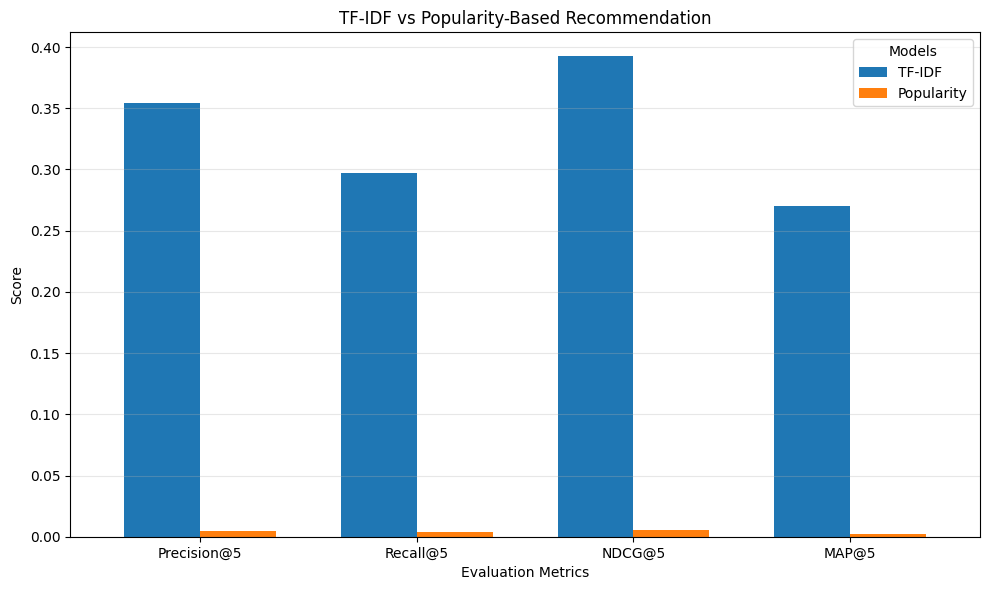

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

comparison_df = pd.DataFrame({
    "TF-IDF": [0.3544, 0.2972, 0.3924, 0.2700],
    "Popularity": [0.0044, 0.0037, 0.0052, 0.0026]
}, index=["Precision@5", "Recall@5", "NDCG@5", "MAP@5"])

print("Recommendation Model Comparison")
display(comparison_df.round(4))

# Plot comparison
comparison_df.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

plt.title("TF-IDF vs Popularity-Based Recommendation")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(title="Models")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Content-Based Filtering vs Collaborative Filtering

### 1. Content-Based Filtering

Content-Based Filtering recommends TED Talks based on the similarity of their content.

In this project:
- TF-IDF is used to convert text into numerical feature vectors.
- Cosine Similarity measures the similarity between talks.
- The system recommends talks with similar titles, topics, descriptions and transcripts.

**Advantages:**
- Does not require user interaction history.
- Works with the available TED Talks dataset.
- Recommendations are based on talk content.
- Easy to interpret and implement.

**Limitations:**
- May recommend similar types of content repeatedly.
- Depends on the quality of text preprocessing.
- Does not learn preferences from other users.

### 2. Collaborative Filtering

Collaborative Filtering recommends items using the preferences and behaviour of multiple users.

It generally requires:
- User IDs
- Talk IDs
- User ratings or interaction history

**Advantages:**
- Can discover unexpected recommendations.
- Learns from collective user preferences.
- Can provide personalized recommendations.

**Limitations:**
- Requires sufficient user interaction data.
- Suffers from cold-start problems for new users and items.
- Cannot be properly implemented using the current dataset because user-item interaction records are unavailable.

### 3. Approach Selection

For this project, Content-Based Filtering using TF-IDF and Cosine Similarity is selected as the final recommendation approach.

The decision is based on its compatibility with the available dataset and its superior evaluation performance compared with the popularity-based baseline.

Collaborative Filtering is identified as a possible future enhancement if user interaction data becomes available.